**03 - Search test + choosing the threshold (part 3.4)**

Problem: similarity_search ALWAYS returns something,even when no fact check exists for the forward

Goal: test real-looking forwards,look at the scores,and pick the "close enough" line(below it the app says UNVERIFIED)

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

Loading the **vector database** (built by create_database.py)

In [2]:
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma

In [3]:
#same model as create_database.py(the forward and the claims must use the same model)
embedding_model=HuggingFaceEmbeddings(model_name="Qwen/Qwen3-Embedding-0.6B")
vectorstore=Chroma(persist_directory="../chroma_db",embedding_function=embedding_model)

W1107 01:43:18.399000 44015 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 310/310 [00:00<00:00, 5599.82it/s]

**Test forwards**

In [4]:
#should_match=True:a real fact check exists(expected_url is that fact check)
#should_match=False:no fact check exists(some are near misses on a similar topic)
test_df=pd.DataFrame({
    "forward":[
        "Sarkar sabhi students ko free laptop de rahi hai, jaldi register karo",
        "RBI का नया नियम: अब सभी बैंक हर शनिवार और रविवार बंद रहेंगे",
        "Modi ji ki appeal ke baad ab har Sunday petrol pump band rahenge",
        "Nimbu, tulsi aur nariyal pani se kidney stone ek din mein khatam ho jata hai",
        "A patent proves 5G towers are being used to brainwash people! Share before it is deleted",
        "प्याज और आलू साथ रखने से आलू जहरीले हो जाते हैं, बच्चों के लिए खतरनाक",
        "RBI ne naye 500 ke plastic note launch kiye hain, Gandhi ji ki photo nahi hai",
        "Akhilesh Yadav ne kaha jeetne par 2000 masjid banayenge aur Muslims ko 30% reservation denge",
        "Aapka traffic challan pending hai, is link par pay karo warna license cancel ho jayega",
        "RBI ne 200 ke note band kar diye hain, kal se nahi chalenge",
        "Roz subah nariyal pani peene se ek mahine mein height 5 cm badh jati hai",
        "IRCTC Diwali offer: har train ticket ke saath free khana milega",
        "Kal se Delhi metro mein mobile phone use karne par 500 rupaye fine lagega",
        "Mumbai mein 15 November ko 24 ghante paani supply band rahega"
    ],
    "lang":["hinglish","hi","hinglish","hinglish","en","hi","hinglish","hinglish","hinglish",
            "hinglish","hinglish","hinglish","hinglish","hinglish"],
    "should_match":[True,True,True,True,True,True,True,True,True,
                    False,False,False,False,False],
    "expected_url":[
        "https://factly.in/beware-of-bogus-websites-offering-free-laptops-smartphones-and-scholarships-in-the-name-of-government/",
        "https://factly.in/rbi-has-not-implemented-a-new-rule-mandating-a-holiday-for-banks-every-saturday/",
        "https://factly.in/viral-post-claiming-petrol-bunks-will-shut-on-sundays-is-fake/",
        "https://www.thip.media/health-news-fact-check/fact-check-can-lemon-holy-basil-and-coconut-water-cure-kidney-stones-in-one-day/113735/",
        "https://www.thip.media/health-news-fact-check/fact-check-does-a-patent-show-that-5g-towers-are-brainwashing-people/54469/",
        "https://factly.in/does-storing-onions-and-potatoes-together-make-the-potatoes-harmful-for-consumption/",
        "https://factly.in/the-rbi-has-not-launched-any-new-%e2%82%b9500-plastic-currency-notes-without-mahatma-gandhis-photograph-this-viral-image-is-ai-generated/",
        "https://www.factcrescendo.com/akhilesh-yadav-has-not-made-any-promise-of-building-2000-masjid-in-uttar-pradesh/",
        "https://factly.in/pending-traffic-challan-links-sent-via-sms-and-whatsapp-are-fake-and-fraudulent/",
        "","","","",""
    ]
})
test_df[["forward","lang","should_match"]]

,forward,lang,should_match
0,Sarkar sabhi students ko free laptop de rahi h...,hinglish,True
1,RBI का नया नियम: अब सभी बैंक हर शनिवार और रविव...,hi,True
2,Modi ji ki appeal ke baad ab har Sunday petrol...,hinglish,True
3,"Nimbu, tulsi aur nariyal pani se kidney stone ...",hinglish,True
4,A patent proves 5G towers are being used to br...,en,True
5,प्याज और आलू साथ रखने से आलू जहरीले हो जाते है...,hi,True
6,RBI ne naye 500 ke plastic note launch kiye ha...,hinglish,True
7,Akhilesh Yadav ne kaha jeetne par 2000 masjid ...,hinglish,True
8,"Aapka traffic challan pending hai, is link par...",hinglish,True
9,"RBI ne 200 ke note band kar diye hain, kal se ...",hinglish,False


**One search** with score first

In [5]:
#similarity_search_with_score = same as similarity_search(teacher's DB.py) but also returns the score
#the score is a DISTANCE:lower = closer(we set cosine in create_database.py so distance = 1 - similarity)
result=vectorstore.similarity_search_with_score(test_df["forward"][0],k=1)
result

[(Document(id='https://factly.in/beware-of-bogus-websites-offering-free-laptops-smartphones-and-scholarships-in-the-name-of-government/', metadata={'rating_raw': 'FALSE', 'verdict': 'FALSE', 'lang': 'en', 'url': 'https://factly.in/beware-of-bogus-websites-offering-free-laptops-smartphones-and-scholarships-in-the-name-of-government/', 'publisher': 'FACTLY', 'date': '2020-09-24 00:00:00'}, page_content='Government is providing free laptops to all the students'),
  0.19760751724243164)]

In [6]:
doc,score=result[0]
print(doc.page_content)
print("distance:",round(score,3))
print("similarity:",round(1-score,3))

Government is providing free laptops to all the students
distance: 0.198
similarity: 0.802


**All test forwards**

In [7]:
#k=1:only the closest fact check matters for the verdict
top_claim=[]
distance=[]
found_url=[]
for forward in test_df["forward"]:
  doc,score=vectorstore.similarity_search_with_score(forward,k=1)[0]
  top_claim.append(doc.page_content)
  distance.append(score)
  found_url.append(doc.metadata["url"])

In [8]:
test_df["top_claim"]=top_claim
test_df["similarity"]=1-np.array(distance)
#did it find the fact check we expected?(only meaningful for should_match rows)
test_df["right_fact_check"]=test_df["expected_url"]==pd.Series(found_url)

In [9]:
pd.set_option("display.max_colwidth",80)
test_df[["forward","should_match","similarity","right_fact_check","top_claim"]].sort_values("similarity",ascending=False)

,forward,should_match,similarity,right_fact_check,top_claim
4,A patent proves 5G towers are being used to brainwash people! Share before i...,True,0.944467,True,a patent show that 5G towers are brainwashing people
6,"RBI ne naye 500 ke plastic note launch kiye hain, Gandhi ji ki photo nahi hai",True,0.841632,True,The Reserve Bank of India (RBI) has launched new ₹500 plastic currency notes...
1,RBI का नया नियम: अब सभी बैंक हर शनिवार और रविवार बंद रहेंगे,True,0.811298,True,Reserve Bank of India (RBI) has implemented a new rule mandating that all ba...
0,"Sarkar sabhi students ko free laptop de rahi hai, jaldi register karo",True,0.802392,True,Government is providing free laptops to all the students
3,"Nimbu, tulsi aur nariyal pani se kidney stone ek din mein khatam ho jata hai",True,0.718919,True,"Lemon, holy basil, and coconut water can cure kidney stones in one day"
7,Akhilesh Yadav ne kaha jeetne par 2000 masjid banayenge aur Muslims ko 30% r...,True,0.714926,True,"खिलेश यादव ने चुनाव जीतने पर 2000 मस्जिद बनाने, दलितों और अन्य पिछड़े वर्गों..."
8,"Aapka traffic challan pending hai, is link par pay karo warna license cancel...",True,0.688368,True,Pending traffic challan payment websites shared via SMS and WhatsApp are off...
2,Modi ji ki appeal ke baad ab har Sunday petrol pump band rahenge,True,0.681842,True,Petrol bunks in several states will remain closed every Sunday following PM ...
12,Kal se Delhi metro mein mobile phone use karne par 500 rupaye fine lagega,False,0.678287,False,Delhi Metro fares increased by 50% after BJP’s victory in Delhi Assembly polls.
9,"RBI ne 200 ke note band kar diye hain, kal se nahi chalenge",False,0.659241,False,RBI issued new guidelines to banks to treat scribbled notes as invalid


**Where should the line be?**

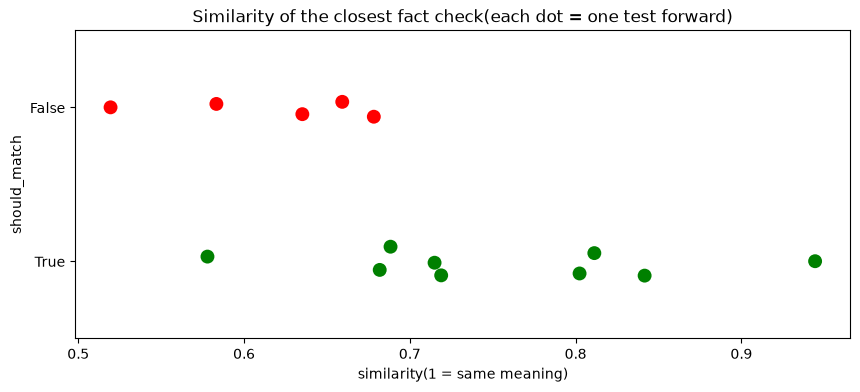

In [10]:
#green dots(should match) should be on the right,red dots(no fact check) on the left
plt.figure(figsize=(10,4))
sns.stripplot(x="similarity",y="should_match",data=test_df,hue="should_match",palette={True:"green",False:"red"},size=10,orient="h",legend=False)
plt.title("Similarity of the closest fact check(each dot = one test forward)")
plt.xlabel("similarity(1 = same meaning)")
plt.show()

In [11]:
#trying different lines(like trying different k in kmeans or C in svm)
#correct = should match,above the line,and found the right fact check
#        OR should NOT match and below the line(app says UNVERIFIED)
for threshold in [0.50,0.55,0.60,0.65,0.70,0.75,0.80]:
  matched=test_df["similarity"]>=threshold
  correct=(test_df["should_match"] & matched & test_df["right_fact_check"]) | (~test_df["should_match"] & ~matched)
  print(f"threshold {threshold:.2f} : {correct.sum()}/{len(test_df)} correct")

threshold 0.50 : 9/14 correct
threshold 0.55 : 10/14 correct
threshold 0.60 : 10/14 correct
threshold 0.65 : 11/14 correct
threshold 0.70 : 11/14 correct
threshold 0.75 : 9/14 correct
threshold 0.80 : 9/14 correct


**Which threshold?** (your decision,write the reason here and in DECISIONS.md)

-

---

**Observations**

1.

---

2.